In [13]:
import numpy as np
import h5py
import shutil
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 14

In [14]:
shutil.copy("learned_mosaic_weights.h5", "copy.h5")

'copy.h5'

In [15]:
results = h5py.File('copy.h5', 'r')

In [16]:
checkpoint = h5py.File("checkpoint_epoch_0080.pt", "r")
checkpoint.keys()

OSError: Unable to synchronously open file (file signature not found)

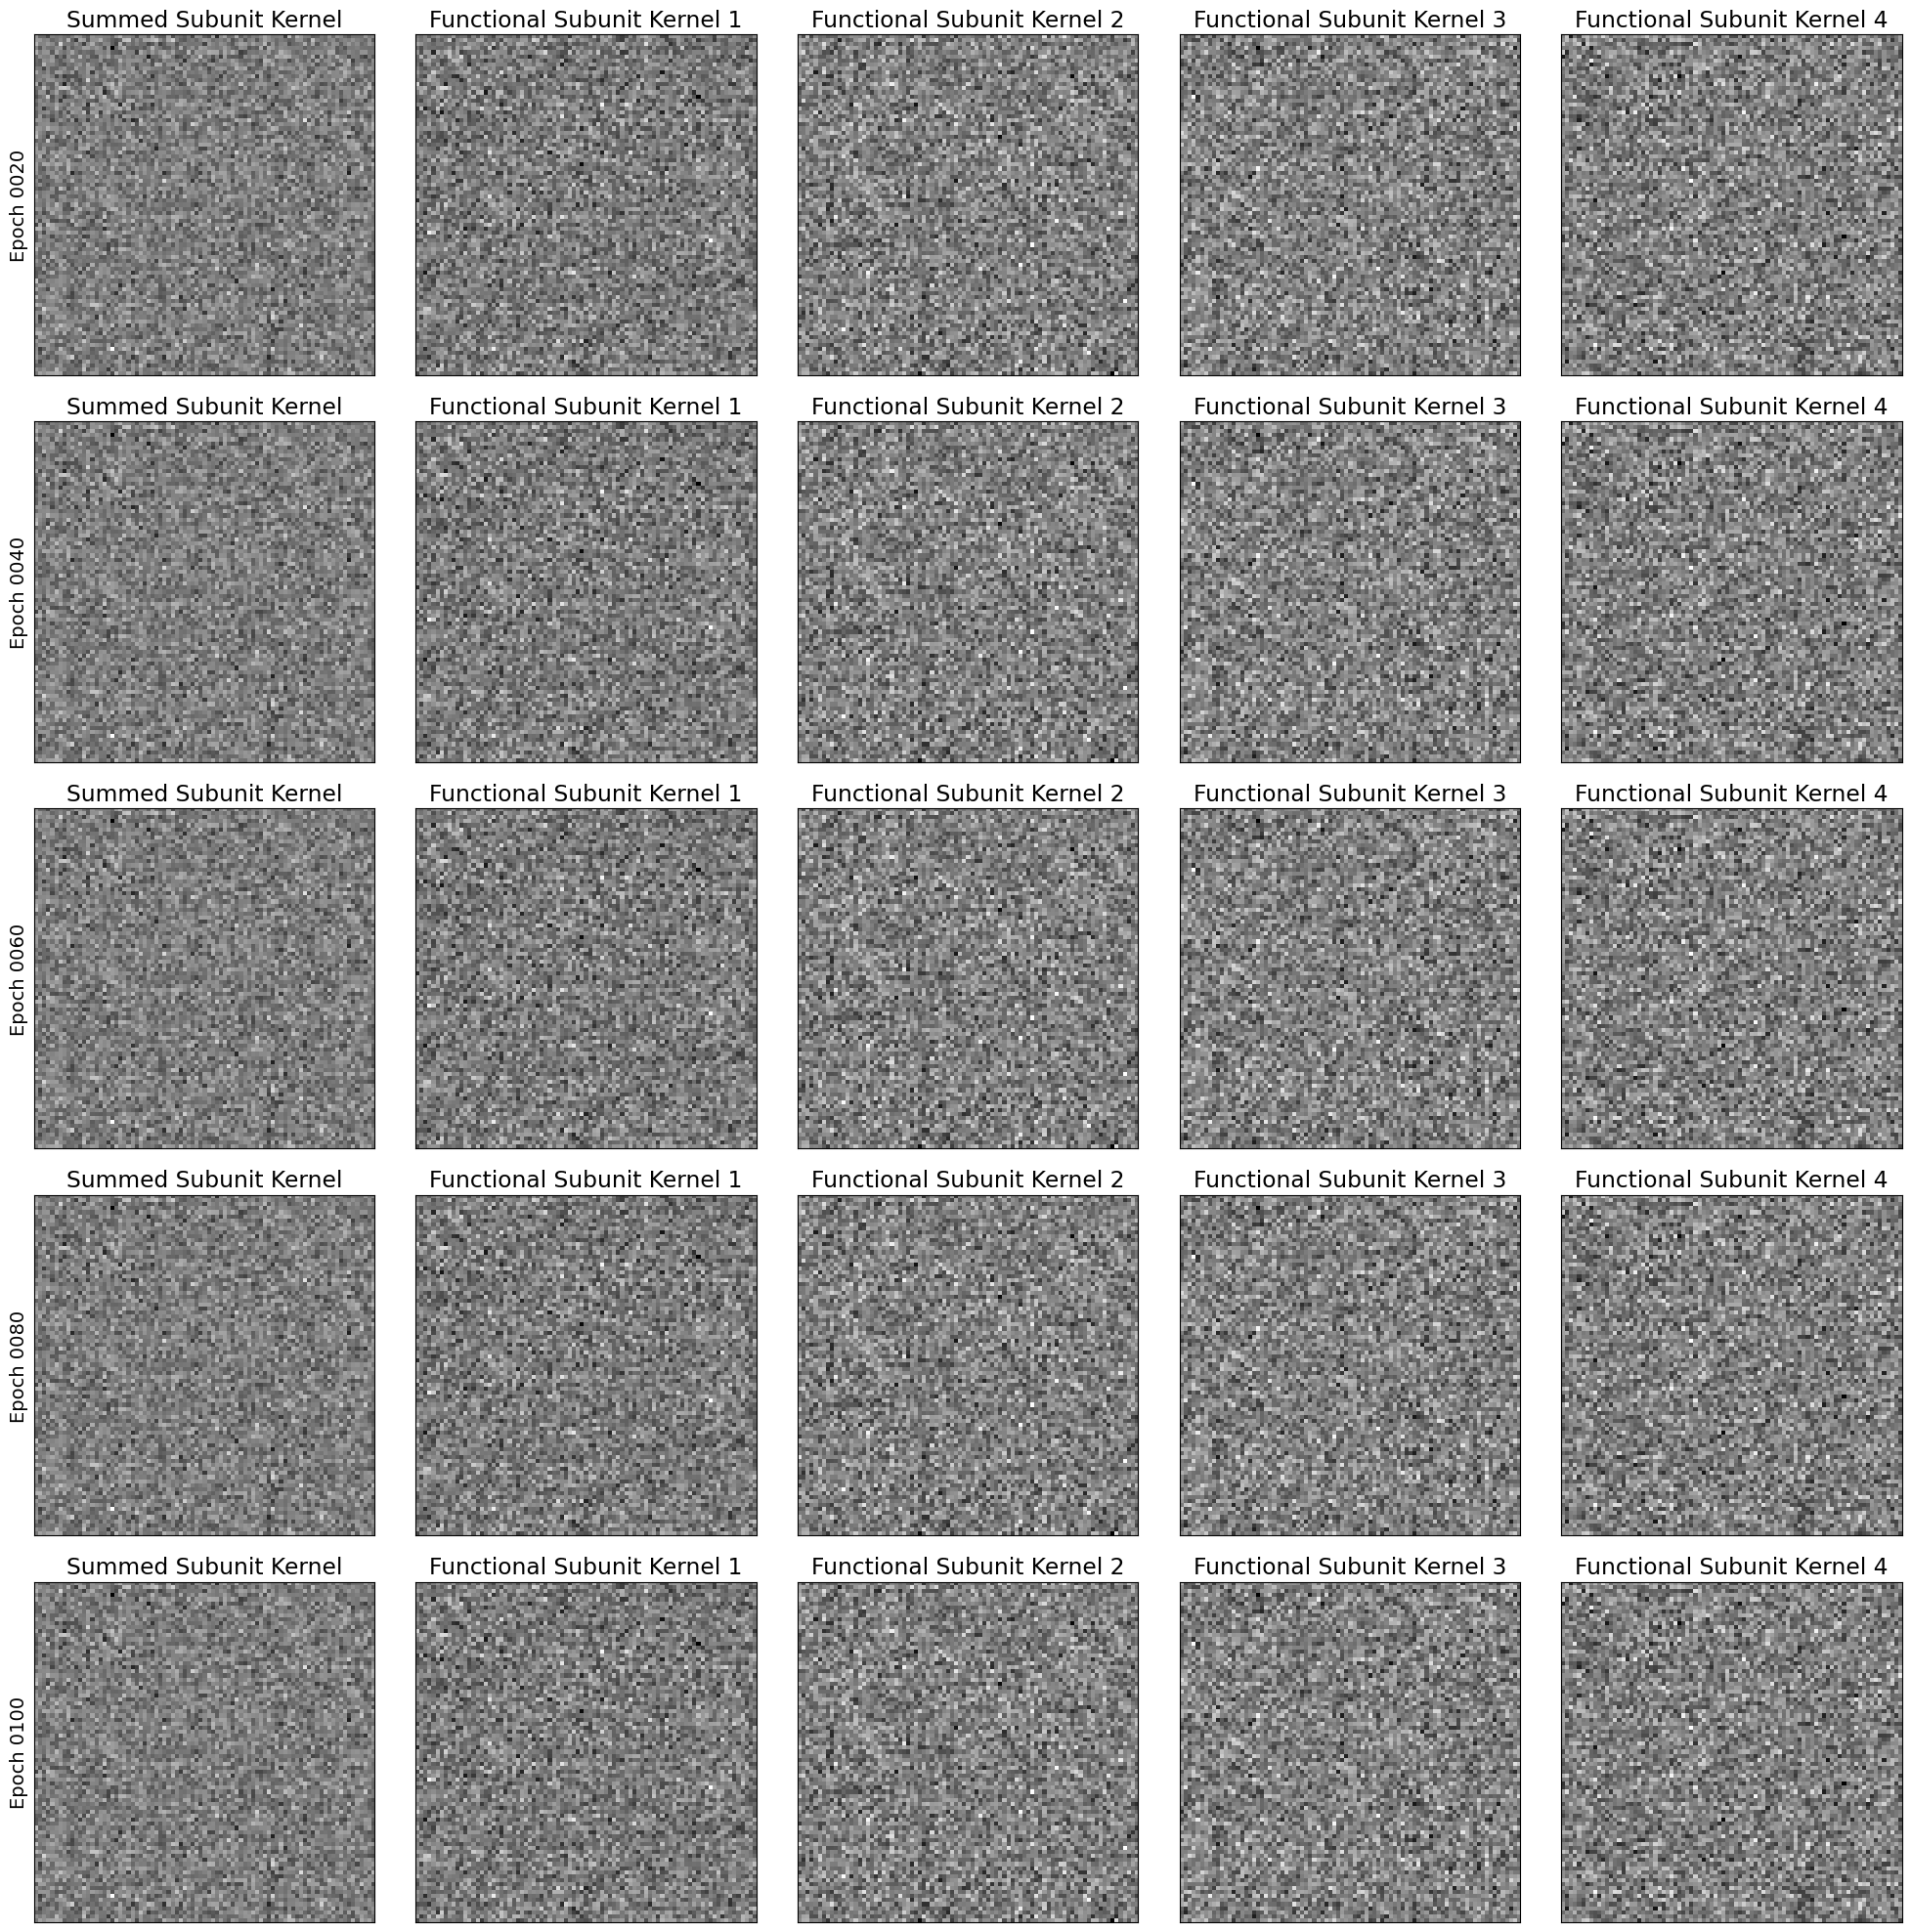

In [ ]:
fig, ax = plt.subplots(5, 5, figsize=(20, 20))

for j,epoch in zip(range(5), ["0020", "0040", "0060", "0080", "0100"]):

    ax[j][0].imshow(np.array(results[f"epoch_{epoch}"]["summed_subunit_kernel"]).squeeze(0), cmap="gray")
    ax[j][0].set_title("Summed Subunit Kernel")
    ax[j][0].set_ylabel(f"Epoch {epoch}")

    for i in range(4):
        ax[j][i+1].imshow(np.array(results[f"epoch_{epoch}"]["functional_subunit_kernels"][i]).squeeze(0), cmap="gray")
        ax[j][i+1].set_title(f"Functional Subunit Kernel {i + 1}")

for a in ax:
    for q in a:
        q.set_xticks([])
        q.set_yticks([])

fig.set_tight_layout(True)
plt.show()

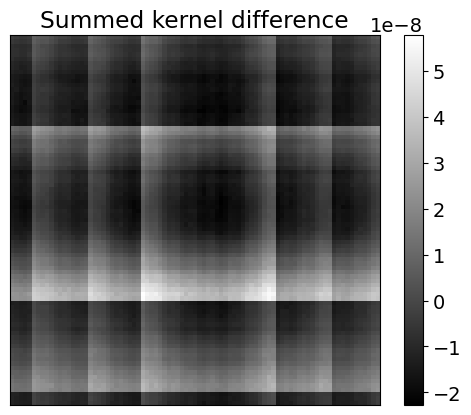

In [ ]:
training_diff = np.array(results[f"epoch_0100"]["summed_subunit_kernel"]).squeeze(0) - np.array(results[f"epoch_0002"]["summed_subunit_kernel"]).squeeze(0)
plt.imshow(training_diff, cmap="gray")

plt.title("Summed kernel difference")
plt.colorbar()

plt.xticks([])
plt.yticks([])
plt.show()

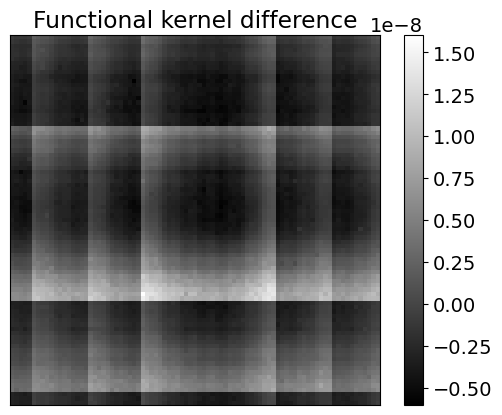

In [ ]:
func_training_diff = [np.array(results[f"epoch_0100"]["functional_subunit_kernels"][i]).squeeze(0) - np.array(results[f"epoch_0002"]["functional_subunit_kernels"][i]).squeeze(0) for i in range(4)]
plt.imshow(func_training_diff[3], cmap="gray")

plt.title("Functional kernel difference")
plt.colorbar()

plt.xticks([])
plt.yticks([])
plt.show()